# Prueba de hipotesis para comparacion de medias.

En este documento se realizará una prueba de hipotesisi de dos medias con el fin de comprobar si
es mayor el salario general de los hombres en comparacion con el de las mujeres.

Para esto, utilizaremos los datos de la ENIGH 2024, Los datos fueron previamente impiados y se eliminaron datos atipicos mediante un IQR, en el documento EDA_Hog.ipynb 

Utilizaremos la prueba T para diferencia de medias, esta prueba asume que ambas muestras cuentan con varianzas similares, por lo que trataremos de comprobarlo con una prueba f para comparacion de varianzas, pero esta prueba asume normalidad en ambas muestras, si bien, el teoorema del limite central nos permite trabajar sin la necesidad de aplicar una prueba de normalidad ya que superamos por mucho la cantidad de 30 datos, aplicaremos una prueba de kolmogorov para tener algo mas de certeza sobre la distribucion de nuestros datos.

In [87]:
# Importar las librerias necesarias
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

In [88]:
# Importar los datos necesarios, mismos que fueron limpiados antertiormente.
# establecer columnas a utilizar
cols = ['sexo_jefe', 'ing_cor']

# Imprimir columnas
datos = pd.read_csv(r'D:\Duend\Documentos\1 IA y ciencia de datos\Semestre 3\proyecto integrador\Clean data\df_eda.csv', usecols= cols, index_col=False)
print('=== Columnas ===')
print(datos.columns)
print('=== Sexos ===')
print(datos['sexo_jefe'].unique())

datos.head()

=== Columnas ===
Index(['sexo_jefe', 'ing_cor'], dtype='str')
=== Sexos ===
<StringArray>
['Hombre', 'Mujer']
Length: 2, dtype: str


,sexo_jefe,ing_cor
0,Hombre,138232.38
1,Hombre,118014.04
2,Mujer,46866.32
3,Hombre,110430.10
4,Mujer,99494.12


In [89]:
# Separar ingresos por hogares dende el jefe del hogar es hombre  y donde es mujer

# datos de hombres
datos_h = datos[datos['sexo_jefe'] == 'Hombre'] 
datos_h = datos_h.reset_index(drop=True) # reiniciar indices

# datos de mujeres
datos_m = datos[datos['sexo_jefe'] == 'Mujer']
datos_m = datos_m.reset_index(drop=True)

In [90]:
# ingresos de hogares con jefe hombre

print('=== Ingresos de hogares con jefes hombre ===')

datos_h.head(10)

=== Ingresos de hogares con jefes hombre ===


,sexo_jefe,ing_cor
0,Hombre,138232.38
1,Hombre,118014.04
2,Hombre,110430.10
3,Hombre,119559.08
4,Hombre,78830.79
5,Hombre,41394.62
6,Hombre,58162.55
7,Hombre,102540.94
8,Hombre,119771.27
9,Hombre,46908.18


In [91]:
# Ingresos de hogares con jefa mujer

print('=== Ingresos de hogares con jefas mujer ===')


datos_m.head(10)

=== Ingresos de hogares con jefas mujer ===


,sexo_jefe,ing_cor
0,Mujer,46866.32
1,Mujer,99494.12
2,Mujer,42414.61
3,Mujer,54344.24
4,Mujer,68922.65
5,Mujer,107360.65
6,Mujer,73933.24
7,Mujer,96416.18
8,Mujer,38472.69
9,Mujer,103179.77


# Exploracion inicial

In [92]:
# estadisticas descriptivas generales
print('=== Ingreso en general ===')
datos['ing_cor'].describe()

=== Ingreso en general ===


count     83454.000000
mean      57616.598252
std       31731.393603
min           0.000000
25%       32754.090000
50%       51577.310000
75%       77609.145000
max      143138.190000
Name: ing_cor, dtype: float64

Text(0.5, 1.0, 'Distribucion del ingreso sin distincion de sexo del jefe del hogar (2024)')

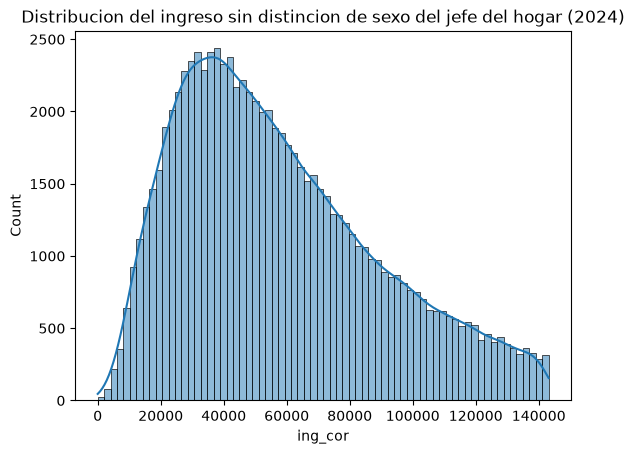

In [93]:
# Distribucion general de los ingresos
sns.histplot(data=datos, x='ing_cor', kde=True).set_title('Distribucion del ingreso sin distincion de sexo del jefe del hogar (2024)')

Text(0.5, 1.0, 'Distribucion del ingreso sin distincion de sexo del jefe del hogar (2024)')

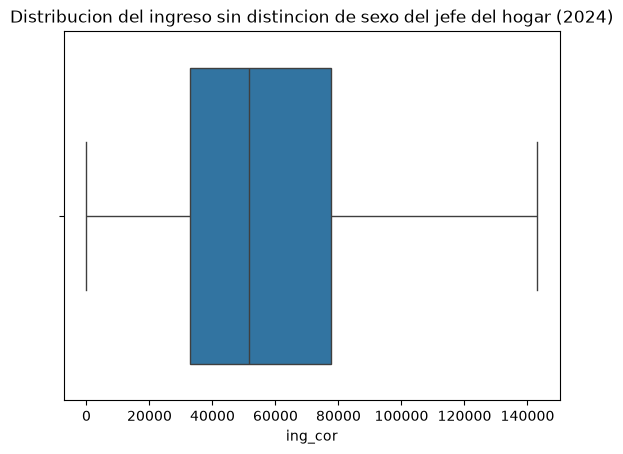

In [94]:
sns.boxplot(data=datos, x= 'ing_cor').set_title('Distribucion del ingreso sin distincion de sexo del jefe del hogar (2024)')

Se observa que los datos sin distinguir entre hombres y mujeres, se encuentran sesgados hacia la derecha, con una media de $57,616 y una mediana mas pequeña, de $51,577.

Esto se interpreta como que la mayoria de los hogares se encuentra al rededor de estas cifras, pero hay pocos hogares que ganan mucho mas, lo que tiende a hacer que la campana tenga una cola mas larga hacia la izquierda y alterando ademas el promedio, haciendolo mas alto que la mediana.

Ademas, en el boxplot podemos observar que la mitad de los tdatos se encuentran entre los $32,754 y los $77,609 pesos cada 3 meses, lo que equivaldria a valores cercanos a entre 1 y casi 3 salarios minimos.

In [95]:
# estadisticas descriptivas generales
print('=== Ingreso de los hombres ===')
datos_h['ing_cor'].describe()

=== Ingreso de los hombres ===


count     55999.000000
mean      58769.150825
std       31848.989833
min           0.000000
25%       33823.680000
50%       52826.080000
75%       79137.845000
max      143138.190000
Name: ing_cor, dtype: float64

In [96]:
# estadisticas descriptivas generales
print('=== Ingreso de las mujeres ===')
datos_m['ing_cor'].describe()

=== Ingreso de las mujeres ===


count     27455.000000
mean      55265.777218
std       31359.710360
min           0.000000
25%       30833.005000
50%       48958.480000
75%       74525.570000
max      143092.250000
Name: ing_cor, dtype: float64

A primera vista parece que no hay una gran diferencia entre medias, pero en medianas la diferencia si es algo mas grande.